<a href="https://colab.research.google.com/github/Petrachju/Projeto-Aplicado---Sistema-de-Recomenda-o-de-Livros/blob/main/ProjetoAplicadoRecomenda%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Recomendação de Livros**

###Bibliotecas


In [1]:
!pip install streamlit scikit-surprise -q

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
import streamlit as st
from surprise import Dataset, Reader, SVD
from surprise.model_selection import GridSearchCV, cross_validate

###Leitura do DataSet

In [2]:
df = pd.read_csv('BookCrossingThemes.csv', sep=';', on_bad_lines='skip', encoding='latin-1')
df.head()

,Book-Title,Book-Author,User-ID,ISBN,Book-Rating,Year-Of-Publication,Publisher,Location,Age,category,description,num_words,num_chars,cleaned_description,Theme
0,The Terminal Man,Michael Crichton,276964,345354621,10.0,1988.0,Ballantine Books,"villa ridge, missouri, usa",34.0,Fiction,Hearry Benson suffers from violent seizures. W...,54.0,335.0,hearry benson suffers violent seizure becomes ...,Psychological Thriller
1,The Chamber,John Grisham,276964,440220602,9.0,1995.0,Dell Publishing Company,"villa ridge, missouri, usa",34.0,American fiction,While the executioners prepare the gas chamber...,26.0,155.0,executioner prepare gas chamber protester gath...,Crime Thrillers and Detective Drama
2,The Girl Who Loved Tom Gordon : A Novel,Stephen King,276964,684867621,8.0,1999.0,Scribner,"villa ridge, missouri, usa",34.0,Fiction,A story of a nine year old who wanders off in ...,19.0,90.0,story nine year old wanders wilderness area he...,Spiritual and Self-Help
3,In the Dark,Richard Laymon,276964,843949163,8.0,2001.0,Leisure Books,"villa ridge, missouri, usa",34.0,California,A tale of suspense follows young librarian Jan...,44.0,250.0,tale suspense follows young librarian jane ker...,Vampire/Paranormal Fantasy
4,Tailchaser's Song,Tad Williams,276964,886773741,7.0,1994.0,Daw Books,"villa ridge, missouri, usa",34.0,Fiction,"Fritti Tailchaser, a ginger tomcat of courage ...",31.0,199.0,fritti tailchaser ginger tomcat courage curios...,Cozy Mysteries


###Análise Exploratória de Dados

In [3]:
print("--- Informações de Livros e Avaliações (df) ---")
display(df[["Book-Title", "Book-Author", "ISBN"]].drop_duplicates().head(3))
print("Valores nulos por coluna:")
print(df.isnull().sum())

# Cálculo da esparsidade da matriz usuário-item usando o DataFrame carregado 'df'
n_usuarios = df["User-ID"].nunique()
n_livros = df["ISBN"].nunique()
n_interacoes = len(df)
esparsidade = (1 - (n_interacoes / (n_usuarios * n_livros))) * 100

print(f"\nUsuários únicos: {n_usuarios:,}")
print(f"Livros únicos (ISBN): {n_livros:,}")
print(f"Total de interações: {n_interacoes:,}")
print(f"Esparsidade da matriz: {esparsidade:.4f}%")

--- Informações de Livros e Avaliações (df) ---


,Book-Title,Book-Author,ISBN
0,The Terminal Man,Michael Crichton,345354621
1,The Chamber,John Grisham,440220602
2,The Girl Who Loved Tom Gordon : A Novel,Stephen King,684867621


Valores nulos por coluna:
Book-Title                0
Book-Author               0
User-ID                   0
ISBN                      0
Book-Rating               1
Year-Of-Publication       1
Publisher                 1
Location                  1
Age                    8368
category               1446
description               1
num_words                 1
num_chars                 1
cleaned_description       1
Theme                     1
dtype: int64

Usuários únicos: 2,610
Livros únicos (ISBN): 5,152
Total de interações: 33,271
Esparsidade da matriz: 99.7526%


- Dado a presença de valores nulos nas categorias Age e Category - vamos descata-las

Duplicatas

In [4]:
# Verificar duplicatas no dataset completo
duplicatas_completas = df.duplicated().sum()
print(f"Linhas completamente duplicadas no DataFrame: {duplicatas_completas}")

# Verificar duplicatas de interações (mesmo usuário avaliando o mesmo livro)
duplicatas_interacao = df.duplicated(subset=['User-ID', 'ISBN']).sum()
print(f"Avaliações duplicadas para o mesmo livro pelo mesmo usuário: {duplicatas_interacao}")

Linhas completamente duplicadas no DataFrame: 0
Avaliações duplicadas para o mesmo livro pelo mesmo usuário: 0


Não há duplicatas

Priorização

In [5]:
# Selecionando apenas as colunas desejadas do DataFrame principal
colunas_desejadas = ['Book-Title', 'Book-Author', 'Book-Rating', 'Theme', 'description']
df_selecionado = df[colunas_desejadas]

# Exibindo as primeiras linhas para verificação
df_selecionado.head()

,Book-Title,Book-Author,Book-Rating,Theme,description
0,The Terminal Man,Michael Crichton,10.0,Psychological Thriller,Hearry Benson suffers from violent seizures. W...
1,The Chamber,John Grisham,9.0,Crime Thrillers and Detective Drama,While the executioners prepare the gas chamber...
2,The Girl Who Loved Tom Gordon : A Novel,Stephen King,8.0,Spiritual and Self-Help,A story of a nine year old who wanders off in ...
3,In the Dark,Richard Laymon,8.0,Vampire/Paranormal Fantasy,A tale of suspense follows young librarian Jan...
4,Tailchaser's Song,Tad Williams,7.0,Cozy Mysteries,"Fritti Tailchaser, a ginger tomcat of courage ..."


In [6]:
# Criando uma cópia explícita do dataset filtrado
df_atualizado = df_selecionado.copy()

# Excluindo quaisquer valores nulos das colunas selecionadas
df_atualizado = df_atualizado.dropna()

# Exibindo informações do novo dataset para confirmar a limpeza
print(f"Tamanho original: {df_selecionado.shape[0]} linhas")
print(f"Tamanho após remover nulos: {df_atualizado.shape[0]} linhas")
print("\nQuantidade de valores nulos por coluna no novo dataset:")
print(df_atualizado.isnull().sum())

# Visualizando as primeiras linhas do dataset limpo e atualizado
display(df_atualizado.head())

Tamanho original: 33271 linhas
Tamanho após remover nulos: 33270 linhas

Quantidade de valores nulos por coluna no novo dataset:
Book-Title     0
Book-Author    0
Book-Rating    0
Theme          0
description    0
dtype: int64


,Book-Title,Book-Author,Book-Rating,Theme,description
0,The Terminal Man,Michael Crichton,10.0,Psychological Thriller,Hearry Benson suffers from violent seizures. W...
1,The Chamber,John Grisham,9.0,Crime Thrillers and Detective Drama,While the executioners prepare the gas chamber...
2,The Girl Who Loved Tom Gordon : A Novel,Stephen King,8.0,Spiritual and Self-Help,A story of a nine year old who wanders off in ...
3,In the Dark,Richard Laymon,8.0,Vampire/Paranormal Fantasy,A tale of suspense follows young librarian Jan...
4,Tailchaser's Song,Tad Williams,7.0,Cozy Mysteries,"Fritti Tailchaser, a ginger tomcat of courage ..."


##Teste de Modelo

###Recorrencia de Palavras

In [7]:
import nltk
from collections import Counter
import re

# Baixando as stopwords padrão em inglês (caso não estejam disponíveis)
try:
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words('english'))
except:
    import nltk
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words('english'))

# Adicionando termos comuns adicionais que não agregam valor à análise temática
stop_words.update(['book', 'story', 'one', 'new', 'life', 'world', 'also', 'finds', 'first', 'back', 'find'])

def extrair_palavras_chave(texto):
    # Converte para minúsculas e remove pontuação e números
    texto_limpo = re.sub(r'[^a-zA-Z\s]', '', str(texto).lower())
    # Tokenização por espaço
    palavras = texto_limpo.split()
    # Filtra palavras pequenas (comprimento < 3) e stopwords
    palavras_filtradas = [w for w in palavras if w not in stop_words and len(w) > 2]
    return palavras_filtradas

# Agrupando as descrições por tema
temas_frequencias = {}

# Agrupando descrições por tema e contando as palavras
for tema, grupo in df_atualizado.groupby('Theme'):
    todas_palavras_tema = []
    for desc in grupo['description']:
        todas_palavras_tema.extend(extrair_palavras_chave(desc))

    # Contando as ocorrências e selecionando as 10 mais comuns
    contagem = Counter(todas_palavras_tema)
    temas_frequencias[tema] = contagem.most_common(10)

# Convertendo para um DataFrame legível
resultados = []
for tema, top_palavras in temas_frequencias.items():
    termos = ", ".join([f"{palavra} ({freq})" for palavra, freq in top_palavras])
    resultados.append({"Tema": tema, "Palavras Mais Frequentes (Frequência)": termos})

df_recorrencia = pd.DataFrame(resultados)
pd.set_option('display.max_colwidth', None)
display(df_recorrencia)

,Tema,Palavras Mais Frequentes (Frequência)
0,American Literature Classics,"novel (1913), american (981), love (971), author (926), york (900), times (863), family (644), bestseller (625), published (610), years (517)"
1,Apocalyptic Fiction,"force (76), tribulation (70), evil (56), continues (42), way (40), battle (33), eternal (32), warfare (32), price (32), bleak (32)"
2,Arthurian Legend and Medieval Fantasy,"tale (319), wicked (231), classic (204), novel (203), fairy (185), love (167), witch (167), magic (166), fantasy (161), evil (151)"
3,Cozy Mysteries,"cat (485), yum (351), qwilleran (300), cats (282), koko (255), series (201), jim (199), mystery (190), murder (162), readers (146)"
4,Crime Thrillers and Detective Drama,"murder (1259), killer (729), man (706), case (659), young (642), years (608), detective (599), police (572), law (537), secret (525)"
5,Culinary Arts,"goldy (361), caterer (152), recipes (145), information (129), may (124), reading (122), york (115), murder (115), copies (114), discussion (114)"
6,Epic Fantasy,"novel (1425), series (718), times (451), books (450), fantasy (448), york (421), author (384), dark (383), novels (371), time (361)"
7,Espionage Thriller,"york (296), cross (291), times (272), killer (267), jack (252), ryan (239), medical (238), alex (237), murder (204), case (199)"
8,Family Dynamics and Loss,"family (204), home (170), son (117), father (105), death (95), american (72), journey (61), another (60), maine (56), mother (51)"
9,Family Dynamics and Relationships,"love (3208), family (1929), woman (1615), novel (1560), man (1440), young (1313), york (1205), two (1202), years (1172), mother (1066)"


###Salva nova Base

In [8]:
# Mapear as palavras mais frequentes (apenas as palavras, sem as frequências numéricas para o TF-IDF)
df_palavras_tema = pd.DataFrame([
    {
        "Theme": tema,
        "Palavras mais frequentes": ", ".join([palavra for palavra, _ in top_palavras])
    }
    for tema, top_palavras in temas_frequencias.items()
])

# Mesclar com o dataframe principal de livros para obter a base completa
df_final = pd.merge(df_atualizado, df_palavras_tema, on="Theme", how="left")

# Renomear a coluna 'description' para coincidir com a solicitação 'Description' se necessário, ou manter conforme solicitado
df_final = df_final.rename(columns={'description': 'Description'})

# Filtrar e manter apenas as colunas solicitadas
colunas_filtradas = ["Book-Title", "Book-Author", "Theme", "Description", "Palavras mais frequentes"]
df_recomendacao = df_final[colunas_filtradas].drop_duplicates().reset_index(drop=True)

# Salvar a nova base em um arquivo CSV
df_recomendacao.to_csv('BookCrossing_TFIDF.csv', index=False, sep=';', encoding='utf-8')

# Visualizar o resultado
print(f"Nova base gerada com {df_recomendacao.shape[0]} registros e salva com sucesso!")
display(df_recomendacao.head())

Nova base gerada com 4935 registros e salva com sucesso!


,Book-Title,Book-Author,Theme,Description,Palavras mais frequentes
0,The Terminal Man,Michael Crichton,Psychological Thriller,"Hearry Benson suffers from violent seizures. When he becomes part of an experimental program that sends electrodes to his brain to calm him, he is in recovery. Until he discovers how to get those soothing pulses more frequently, and then escapes the hopsital--on a murderous rampage with a deadly agenda.... From the Paperback edition.","man, fear, town, killer, nothing, knows, like, never, secret, death"
1,The Chamber,John Grisham,Crime Thrillers and Detective Drama,"While the executioners prepare the gas chamber, while the protesters gather and the TV cameras wait. Adam has only days, hours, minutes to save his client.","murder, killer, man, case, young, years, detective, police, law, secret"
2,The Girl Who Loved Tom Gordon : A Novel,Stephen King,Spiritual and Self-Help,A story of a nine year old who wanders off in a wilderness area and hew spirit to survive.,"author, novel, women, love, two, power, human, young, mother, black"
3,In the Dark,Richard Laymon,Vampire/Paranormal Fantasy,"A tale of suspense follows young librarian Jane Kerry, who discovers an envelope containing money and instructions signed by the Master of Games, as she is hurled into a dark world where she must play a deadly and disturbing game in order to survive.","novel, vampire, york, series, author, times, bestselling, love, rice, three"
4,Tailchaser's Song,Tad Williams,Cozy Mysteries,"Fritti Tailchaser, a ginger tomcat of courage and curiosity, becomes alarmed as cats begin vanishing mysteriously. When his catfriend Hushpad disappears, he sets out on a magical quest to rescue her.","cat, yum, qwilleran, cats, koko, series, jim, mystery, murder, readers"


##Modelo - Abordagem TF-IDF de similaridade

##Amostragem

In [9]:
def limpar_texto(texto: str) -> str:
    if not isinstance(texto, str):
        return ""
    texto = texto.lower()
    # Mantém letras, números e espaços; troca pontuação/símbolos por espaço
    texto = re.sub(r"[^a-zà-ú0-9\s]", " ", texto)
    # Colapsa múltiplos espaços em um único espaço
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

# 1. Copiar a base gerada anteriormente e garantir strings
cols_original = ["Book-Title", "Book-Author", "Theme", "Description", "Palavras mais frequentes"]
df_modelo = df_recomendacao.copy()

for col in cols_original:
    df_modelo[col] = df_modelo[col].fillna("").astype(str).str.strip()

# Remove linhas totalmente vazias nos campos principais
df_modelo = df_modelo[(df_modelo["Description"] != "") | (df_modelo["Theme"] != "")].reset_index(drop=True)

# 2. Limpeza de cada campo utilizando a função auxiliar
for col in cols_original:
    df_modelo[f"{col}_limpo"] = df_modelo[col].apply(limpar_texto)

# 3. Texto composto - Incorporando o peso do Theme e das Palavras mais frequentes no modelo
df_modelo["texto_modelo"] = (
    df_modelo["Book-Title_limpo"] + " " +
    df_modelo["Book-Author_limpo"] + " " +
    (df_modelo["Theme_limpo"] + " ") * 2 + " " +
    df_modelo["Description_limpo"] + " " +
    df_modelo["Palavras mais frequentes_limpo"]
).str.strip()

# 4. Configuração e Ajuste do TF-IDF
vectorizer = TfidfVectorizer(
    stop_words="english",
    lowercase=True,
    ngram_range=(1, 2),  # unigramas e bigramas
    min_df=2,            # ignora termos raros que aparecem em menos de 2 livros
    max_df=0.85,         # ignora termos genéricos que aparecem em mais de 85% dos livros
)

tfidf_matrix = vectorizer.fit_transform(df_modelo["texto_modelo"])
similarity_matrix = linear_kernel(tfidf_matrix, tfidf_matrix)

print(f"Matriz TF-IDF gerada com sucesso! Formato da matriz: {tfidf_matrix.shape}")

Matriz TF-IDF gerada com sucesso! Formato da matriz: (4935, 41689)


###Visualizar nova base

In [10]:
cols_visualizacao = [
    "Book-Title_limpo",
    "Book-Author_limpo",
    "Theme_limpo",
    "Palavras mais frequentes_limpo",
    "texto_modelo",
]

# Exibe as 5 primeiras linhas com texto completo (sem cortar com "...")
with pd.option_context(
    "display.max_columns", None, "display.max_colwidth", 120, "display.width", 1000
):
  display(df_modelo[cols_visualizacao].head(5))

,Book-Title_limpo,Book-Author_limpo,Theme_limpo,Palavras mais frequentes_limpo,texto_modelo
0,the terminal man,michael crichton,psychological thriller,man fear town killer nothing knows like never secret death,the terminal man michael crichton psychological thriller psychological thriller hearry benson suffers from violent ...
1,the chamber,john grisham,crime thrillers and detective drama,murder killer man case young years detective police law secret,the chamber john grisham crime thrillers and detective drama crime thrillers and detective drama while the executio...
2,the girl who loved tom gordon a novel,stephen king,spiritual and self help,author novel women love two power human young mother black,the girl who loved tom gordon a novel stephen king spiritual and self help spiritual and self help a story of a nin...
3,in the dark,richard laymon,vampire paranormal fantasy,novel vampire york series author times bestselling love rice three,in the dark richard laymon vampire paranormal fantasy vampire paranormal fantasy a tale of suspense follows young l...
4,tailchaser s song,tad williams,cozy mysteries,cat yum qwilleran cats koko series jim mystery murder readers,tailchaser s song tad williams cozy mysteries cozy mysteries fritti tailchaser a ginger tomcat of courage and curio...


###visualizar matriz

In [11]:
amostra_idx = df_modelo.index[:8]
titulos_curtos = df_modelo.loc[amostra_idx, "Book-Title"].str.slice(0, 28)

df_sim_amostra = pd.DataFrame(
    similarity_matrix[np.ix_(amostra_idx, amostra_idx)],
    index=titulos_curtos,
    columns=titulos_curtos,
)

display(df_sim_amostra.round(3))

Book-Title,The Terminal Man,The Chamber,The Girl Who Loved Tom Gordo,In the Dark,Tailchaser's Song,"Stone of Farewell (Memory, S",The Dragon Token (Dragon Sta,Roses Are Red (Alex Cross No
Book-Title,,,,,,,,
The Terminal Man,1.000,0.010,0.000,0.023,0.000,0.000,0.013,0.007
The Chamber,0.010,1.000,0.002,0.001,0.002,0.000,0.000,0.009
The Girl Who Loved Tom Gordo,0.000,0.002,1.000,0.025,0.000,0.014,0.003,0.003
In the Dark,0.023,0.001,0.025,1.000,0.002,0.000,0.130,0.089
Tailchaser's Song,0.000,0.002,0.000,0.002,1.000,0.065,0.007,0.009
"Stone of Farewell (Memory, S",0.000,0.000,0.014,0.000,0.065,1.000,0.040,0.001
The Dragon Token (Dragon Sta,0.013,0.000,0.003,0.130,0.007,0.040,1.000,0.049
Roses Are Red (Alex Cross No,0.007,0.009,0.003,0.089,0.009,0.001,0.049,1.000


###HeatMap da subamostra

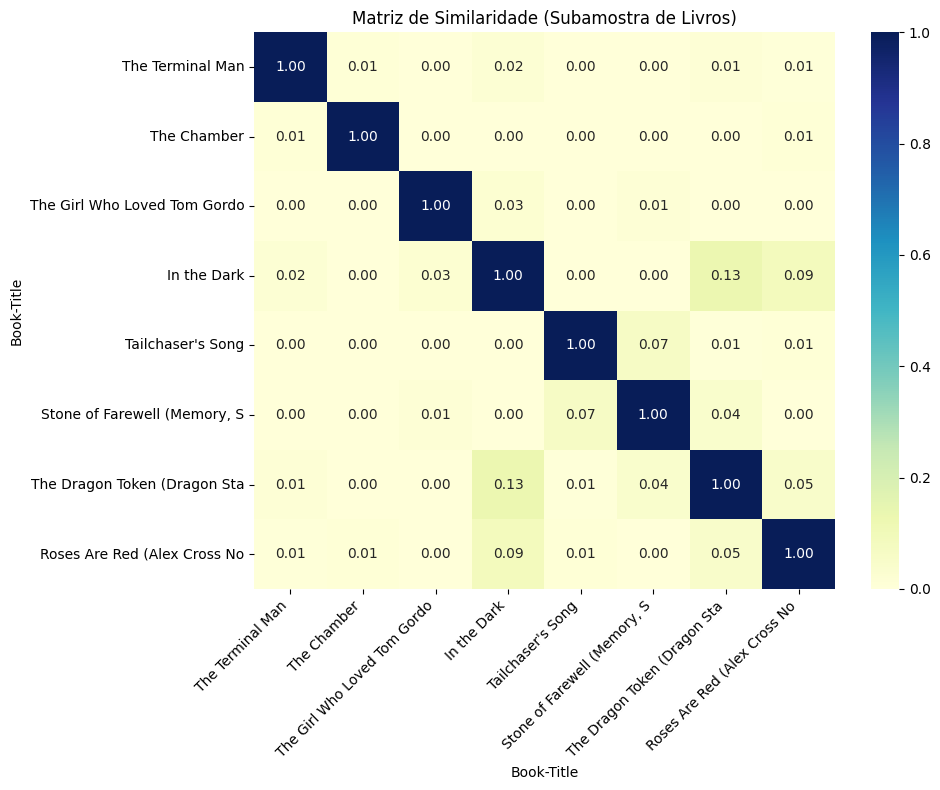

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_sim_amostra, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1
)
plt.title("Matriz de Similaridade (Subamostra de Livros)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

###Matriz de Peso

In [13]:
termos = vectorizer.get_feature_names_out()

# Recorte: 5 primeiros livros x 15 primeiros termos do vocabulário
df_tfidf_recorte = pd.DataFrame(
    tfidf_matrix[:5, :15].toarray(),
    index=df_modelo["Book-Title"].iloc[:5].str.slice(0, 25),
    columns=termos[:15],
)

display(df_tfidf_recorte.round(3))

,000,000 000,000 acre,000 ad,000 copies,000 feet,000 people,000 printing,000 years,02,02 york,04,04 donation,09,10
Book-Title,,,,,,,,,,,,,,,
The Terminal Man,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
The Chamber,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
The Girl Who Loved Tom Go,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
In the Dark,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Tailchaser's Song,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


###Métricas de Estrutura e Esparsidade

In [14]:
n_linhas, n_colunas = tfidf_matrix.shape
nnz = tfidf_matrix.nnz  # quantidade de valores não-zero
densidade = nnz / (n_linhas * n_colunas)
esparsidade = 1 - densidade

print(f"TF-IDF shape     : {tfidf_matrix.shape}")
print(f"Valores não-zero : {nnz}")
print(f"Esparsidade      : {esparsidade:.2%}")
print(f"Similarity shape : {similarity_matrix.shape}")

TF-IDF shape     : (4935, 41689)
Valores não-zero : 401322
Esparsidade      : 99.80%
Similarity shape : (4935, 4935)


##Modelo de Recomendação

###Top-**K**

In [15]:
def recomendar_livros(
    titulo: str,
    df: pd.DataFrame,
    sim_matrix,
    top_k: int = 5,
    mesmo_tema_apenas: bool = False,
    exibir_descricao: bool = False,
) -> pd.DataFrame:
  """Retorna os top-K livros mais similares a um título com base em similarity_matrix."""
  if df.empty or top_k <= 0:
    return pd.DataFrame()

  # Garante alinhamento posicional com a matriz de similaridade (0 a len(df)-1)
  df_reset = df.reset_index(drop=True)
  titulos_norm = df_reset["Book-Title"].fillna("").astype(str).str.strip().str.lower()
  consulta_norm = titulo.strip().lower()

  # 1. Tenta correspondência exata; se não achar, busca correspondência parcial
  matches = df_reset.index[titulos_norm == consulta_norm].tolist()
  if not matches:
    matches = df_reset.index[
        titulos_norm.str.contains(consulta_norm, regex=False, na=False)
    ].tolist()

  if not matches:
    print(f"Nenhum livro encontrado para: '{titulo}'")
    return pd.DataFrame()

  idx_base = matches[0]
  livro_base = df_reset.loc[idx_base]

  print(f"Livro de referência: {livro_base['Book-Title']} — {livro_base['Book-Author']}")
  print(f"Tema (nó)          : {livro_base.get('Theme', '')}")
  if "Palavras mais frequentes" in df_reset.columns:
    print(f"Palavras frequentes: {livro_base['Palavras mais frequentes']}")
  print("-" * 70)

  # 2. Obtém scores de similaridade e remove o próprio livro de referência
  scores = list(enumerate(sim_matrix[idx_base]))
  scores = [(i, float(s)) for i, s in scores if i != idx_base]

  # 3. Filtro opcional para restringir ao mesmo nó temático
  if mesmo_tema_apenas and "Theme" in df_reset.columns:
    tema_base = str(livro_base["Theme"]).strip().lower()
    scores = [
        (i, s)
        for i, s in scores
        if str(df_reset.loc[i, "Theme"]).strip().lower() == tema_base
    ]

  # 4. Ordena por maior score decrescente e seleciona os top-K
  scores.sort(key=lambda x: x[1], reverse=True)
  top_scores = scores[:top_k]

  indices_rec = [i for i, _ in top_scores]
  similaridades = [round(s, 4) for _, s in top_scores]

  colunas_saida = ["Book-Title", "Book-Author", "Theme"]
  if "Palavras mais frequentes" in df_reset.columns:
    colunas_saida.append("Palavras mais frequentes")
  if exibir_descricao and "Description" in df_reset.columns:
    colunas_saida.append("Description")

  resultado = df_reset.loc[indices_rec, colunas_saida].copy()
  resultado.insert(0, "Rank", range(1, len(resultado) + 1))
  resultado["Similaridade"] = similaridades
  if "Theme" in df_reset.columns:
    tema_base = str(livro_base["Theme"]).strip().lower()
    resultado["Mesmo_Tema"] = (
        resultado["Theme"].astype(str).str.strip().str.lower() == tema_base
    )

  return resultado.reset_index(drop=True)

###Visualização

In [16]:
# Exemplo 1: Top 5 geral (permite conexões dentro do tema e transversais)
recs = recomendar_livros(
    titulo="The Terminal Man",
    df=df_modelo,
    sim_matrix=similarity_matrix,
    top_k=5,
)
display(recs)

# Exemplo 2: Top 5 restrito ao mesmo Theme (nó temático) com descrição
recs_tema = recomendar_livros(
    titulo="Stone of Farewell",
    df=df_modelo,
    sim_matrix=similarity_matrix,
    top_k=5,
    mesmo_tema_apenas=True,
    exibir_descricao=True,
)
display(recs_tema)

Livro de referência: The Terminal Man — Michael Crichton
Tema (nó)          : Psychological Thriller
Palavras frequentes: man, fear, town, killer, nothing, knows, like, never, secret, death
----------------------------------------------------------------------


,Rank,Book-Title,Book-Author,Theme,Palavras mais frequentes,Similaridade,Mesmo_Tema
0,1,And Then There Were None,Agatha Christie,Psychological Thriller,"man, fear, town, killer, nothing, knows, like, never, secret, death",0.3905,True
1,2,The Exorcist,William Peter Blatty,Psychological Thriller,"man, fear, town, killer, nothing, knows, like, never, secret, death",0.3890,True
2,3,False Memory,Dean R. Koontz,Psychological Thriller,"man, fear, town, killer, nothing, knows, like, never, secret, death",0.3728,True
3,4,Desperation,Stephen King,Psychological Thriller,"man, fear, town, killer, nothing, knows, like, never, secret, death",0.3617,True
4,5,My Sweet Audrina,V.C. Andrews,Psychological Thriller,"man, fear, town, killer, nothing, knows, like, never, secret, death",0.3548,True


Livro de referência: Stone of Farewell (Memory, Sorrow, and Thorn, Book 2) — Tad Williams
Tema (nó)          : Apocalyptic Fiction
Palavras frequentes: force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak
----------------------------------------------------------------------


,Rank,Book-Title,Book-Author,Theme,Palavras mais frequentes,Description,Similaridade,Mesmo_Tema
0,1,1984,George Orwell,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",Eternal warfare is the price of bleak prosperity in this satire of totalitarian barbarism.,0.5316,True
1,2,The Tenth Insight : Holding the Vision,James Redfield,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",Sequel to The Celestine prophecy.,0.5166,True
2,3,Odd Thomas,Dean Koontz,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",A hero on the border of life and death must avert a looming cataclysm.,0.5089,True
3,4,The Last Precinct,Patricia Daniels Cornwell,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",Scarpetta knows the world is evil and often overwhelming.,0.5076,True
4,5,The Forever War,Joe Haldeman,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",Mandella feels hopelessly frustrated as a foot soldier in a century-long interplanetary war.,0.5016,True


###Avaliação do Modelo

Baseline

In [17]:
import random

def recomendar_baseline_aleatorio(df: pd.DataFrame, top_k: int = 5) -> pd.DataFrame:
    """Retorna K livros escolhidos de forma completamente aleatória como um baseline."""
    if df.empty or top_k <= 0:
        return pd.DataFrame()

    # Garante que não tentaremos sortear mais elementos do que existem na base
    k_ajustado = min(top_k, len(df))

    # Sorteia índices aleatórios
    indices_aleatorios = random.sample(list(df.index), k_ajustado)

    colunas_saida = ["Book-Title", "Book-Author", "Theme"]
    if "Palavras mais frequentes" in df.columns:
        colunas_saida.append("Palavras mais frequentes")

    resultado = df.loc[indices_aleatorios, colunas_saida].copy()
    resultado.insert(0, "Rank", range(1, len(resultado) + 1))
    # Atribui uma similaridade aleatória ou nula para fins de preenchimento de métricas
    resultado["Similaridade"] = [round(random.uniform(0, 1), 4) for _ in range(k_ajustado)]

    return resultado.reset_index(drop=True)

# Testando o baseline
print("=== RECOMENDAÇÃO BASELINE ALEATÓRIA (Grupo de Controle) ===")
display(recomendar_baseline_aleatorio(df_modelo, top_k=5))

=== RECOMENDAÇÃO BASELINE ALEATÓRIA (Grupo de Controle) ===


,Rank,Book-Title,Book-Author,Theme,Palavras mais frequentes,Similaridade
0,1,"The Amber Spyglass (His Dark Materials, Book 3)",Philip Pullman,Epic Fantasy,"novel, series, times, books, fantasy, york, author, dark, novels, time",0.5070
1,2,Star,Danielle Steel,War and Historical Drama,"war, michael, years, novel, hanna, young, helen, secrets, germany, way",0.2099
2,3,Blue Shoe,Anne Lamott,Family Dynamics and Relationships,"love, family, woman, novel, man, young, york, two, years, mother",0.5496
3,4,The Debt to Pleasure: A Novel,John Lanchester,"Humor, Satire and Comics","times, york, author, bestseller, time, american, hilarious, men, man, like",0.1422
4,5,When the Bough Breaks,Jonathan Kellerman,Crime Thrillers and Detective Drama,"murder, killer, man, case, young, years, detective, police, law, secret",0.4817


In [18]:
def recomendar_baseline_busca_aleatoria(df: pd.DataFrame, vectorizer, top_k: int = 5) -> pd.DataFrame:
    """Sorteia termos aleatórios do vocabulário do TF-IDF e busca livros que contenham esses termos no 'texto_modelo'."""
    if df.empty or top_k <= 0:
        return pd.DataFrame()

    # Obter termos do vocabulário
    termos = list(vectorizer.get_feature_names_out())
    if not termos:
        return pd.DataFrame()

    # Sorteia de 1 a 3 termos aleatórios para formar a busca
    qtd_termos = random.randint(1, 3)
    termos_sorteados = random.sample(termos, qtd_termos)
    busca_aleatoria = " ".join(termos_sorteados)

    print(f"Termos de busca aleatórios sorteados: '{busca_aleatoria}'")
    print("-" * 70)

    # Encontra livros que contêm pelo menos um dos termos sorteados no 'texto_modelo'
    df_reset = df.reset_index(drop=True)
    indices_match = []
    for termo in termos_sorteados:
        matches = df_reset.index[df_reset["texto_modelo"].str.contains(rf"\b{re.escape(termo)}\b", regex=True, na=False)].tolist()
        indices_match.extend(matches)

    indices_match = list(set(indices_match))

    # Se não encontrar nenhum, recorremos a um sorteio aleatório simples informando o ocorrido
    if not indices_match:
        print("Nenhum livro conteve as palavras sorteadas. Retornando livros aleatórios como fallback.")
        return recomendar_baseline_aleatorio(df, top_k=top_k)

    # Limita ao top_k solicitado
    k_ajustado = min(top_k, len(indices_match))
    indices_selecionados = random.sample(indices_match, k_ajustado)

    colunas_saida = ["Book-Title", "Book-Author", "Theme"]
    if "Palavras mais frequentes" in df_reset.columns:
        colunas_saida.append("Palavras mais frequentes")

    resultado = df_reset.loc[indices_selecionados, colunas_saida].copy()
    resultado.insert(0, "Rank", range(1, len(resultado) + 1))
    # Atribui similaridade aleatória para correspondência visual de comparação
    resultado["Similaridade"] = [round(random.uniform(0.01, 0.3), 4) for _ in range(k_ajustado)]

    return resultado.reset_index(drop=True)

# Testando o Baseline 2 baseado em busca por palavras aleatórias
print("=== BASELINE 2: RECOMENDAÇÃO BASEADA EM PALAVRAS ALEATÓRIAS ===")
display(recomendar_baseline_busca_aleatoria(df_modelo, vectorizer, top_k=5))

=== BASELINE 2: RECOMENDAÇÃO BASEADA EM PALAVRAS ALEATÓRIAS ===
Termos de busca aleatórios sorteados: 'live story unforgettable fbi agent'
----------------------------------------------------------------------


,Rank,Book-Title,Book-Author,Theme,Palavras mais frequentes,Similaridade
0,1,Face the Fire (Three Sisters Island Trilogy),Nora Roberts,Vampire/Paranormal Fantasy,"novel, vampire, york, series, author, times, bestselling, love, rice, three",0.1090
1,2,The Diving Bell and the Butterfly : A Memoir of Life in Death,JEAN-DOMINIQUE BAUBY,Spiritual and Self-Help,"author, novel, women, love, two, power, human, young, mother, black",0.2573
2,3,Songs in Ordinary Time (Oprah's Book Club (Paperback)),Mary McGarry Morris,Family Dynamics and Relationships,"love, family, woman, novel, man, young, york, two, years, mother",0.1406
3,4,The Summerhouse,Jude Deveraux,Family Dynamics and Relationships,"love, family, woman, novel, man, young, york, two, years, mother",0.2579
4,5,Running from the Law,Lisa Scottoline,Crime Thrillers and Detective Drama,"murder, killer, man, case, young, years, detective, police, law, secret",0.1811


Baselise 2

In [19]:
def recomendar_baseline_contagem_tema(
    titulo: str,
    df: pd.DataFrame,
    temas_frequencias: dict,
    top_k: int = 5
) -> pd.DataFrame:
    """
    Baseline que pontua e ordena os livros pertencentes ao mesmo tema do livro de referência
    com base na contagem simples de aparições das 10 palavras mais frequentes daquele tema.
    """
    if df.empty or top_k <= 0:
        return pd.DataFrame()

    df_reset = df.reset_index(drop=True)
    titulos_norm = df_reset["Book-Title"].fillna("").astype(str).str.strip().str.lower()
    consulta_norm = titulo.strip().lower()

    # Encontra o livro de referência
    matches = df_reset.index[titulos_norm == consulta_norm].tolist()
    if not matches:
        matches = df_reset.index[titulos_norm.str.contains(consulta_norm, regex=False, na=False)].tolist()

    if not matches:
        print(f"Nenhum livro encontrado para: '{titulo}'")
        return pd.DataFrame()

    idx_base = matches[0]
    livro_base = df_reset.loc[idx_base]
    tema_base = livro_base["Theme"]

    print(f"Livro de referência: {livro_base['Book-Title']} — {livro_base['Book-Author']}")
    print(f"Tema de busca       : {tema_base}")
    print("-" * 70)

    # Obter os livros pertencentes ao mesmo tema (excluindo o livro de referência)
    df_mesmo_tema = df_reset[(df_reset["Theme"] == tema_base) & (df_reset.index != idx_base)].copy()

    if df_mesmo_tema.empty:
        print(f"Nenhum outro livro encontrado no tema '{tema_base}'.")
        return pd.DataFrame()

    # Extrair as top palavras do tema do dicionário temas_frequencias
    palavras_chave_tema = [palavra.lower() for palavra, _ in temas_frequencias.get(tema_base, [])]

    # Função para contar a ocorrência das palavras chave no texto modelo de cada livro
    def contar_ocorrencias(texto):
        texto_limpo = str(texto).lower()
        # Conta quantas vezes cada palavra chave aparece individualmente no texto
        return sum(len(re.findall(rf"\b{re.escape(p)}\b", texto_limpo)) for p in palavras_chave_tema)

    # Aplicar contagem
    df_mesmo_tema["Contagem_Termos"] = df_mesmo_tema["texto_modelo"].apply(contar_ocorrencias)

    # Ordenar decrescentemente por quantidade de ocorrências
    df_ordenado = df_mesmo_tema.sort_values(by="Contagem_Termos", ascending=False).head(top_k)

    colunas_saida = ["Book-Title", "Book-Author", "Theme"]
    if "Palavras mais frequentes" in df_reset.columns:
        colunas_saida.append("Palavras mais frequentes")

    resultado = df_ordenado[colunas_saida].copy()
    resultado.insert(0, "Rank", range(1, len(resultado) + 1))
    resultado["Contagem_Frequentes"] = df_ordenado["Contagem_Termos"]

    return resultado.reset_index(drop=True)

# Exemplo de teste para o novo Baseline de contagem
print("=== BASELINE 3: ORDENAÇÃO POR CONTAGEM SIMPLES DE TERMOS DO TEMA ===")
recs_contagem = recomendar_baseline_contagem_tema(
    titulo="Stone of Farewell",
    df=df_modelo,
    temas_frequencias=temas_frequencias,
    top_k=5
)
display(recs_contagem)

=== BASELINE 3: ORDENAÇÃO POR CONTAGEM SIMPLES DE TERMOS DO TEMA ===
Livro de referência: Stone of Farewell (Memory, Sorrow, and Thorn, Book 2) — Tad Williams
Tema de busca       : Apocalyptic Fiction
----------------------------------------------------------------------


,Rank,Book-Title,Book-Author,Theme,Palavras mais frequentes,Contagem_Frequentes
0,1,Nicolae: The Rise of Antichrist (Left Behind #3),Tim Lahaye,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",16
1,2,Nicolae: The Rise of Antichrist (Left Behind No. 3),Tim F. Lahaye,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",16
2,3,1984,George Orwell,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",14
3,4,"Assassins: Assignment: Jerusalem, Target: Antichrist (Left Behind No. 6)",Tim Lahaye,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",13
4,5,The Remnant: On the Brink of Armageddon (Left Behind No. 10),Tim LaHaye,Apocalyptic Fiction,"force, tribulation, evil, continues, way, battle, eternal, warfare, price, bleak",13


In [20]:
import numpy as np
import pandas as pd


def similaridade_real_lista(
    idx_base: int, indices_rec: list[int], sim_matrix
) -> float:
  if not indices_rec:
    return 0.0
  vals = [float(sim_matrix[idx_base, i]) for i in indices_rec if i != idx_base]
  return float(np.mean(vals)) if vals else 0.0


def aderencia_tematica_lista(
    tema_base: str, df_rec: pd.DataFrame
) -> float:
  if df_rec.empty or "Theme" not in df_rec.columns:
    return 0.0
  tema_norm = str(tema_base).strip().lower()
  acertos = (
      df_rec["Theme"].astype(str).str.strip().str.lower() == tema_norm
  ).sum()
  return float(acertos / len(df_rec))


def avaliar_abordagens(
    df: pd.DataFrame,
    sim_matrix,
    vectorizer,
    temas_frequencias: dict,
    indices_consulta: list[int],
    top_k: int = 5,
    seed: int = 42,
) -> pd.DataFrame:
  random.seed(seed)
  np.random.seed(seed)

  df_reset = df.reset_index(drop=True)
  abordagens = {
      "Modelo TF-IDF + Similaridade": {
          "aderencia": [],
          "sim_real": [],
          "unicos": set(),
      },
      "Baseline 1: Aleatório": {"aderencia": [], "sim_real": [], "unicos": set()},
      "Baseline 2: Busca Aleatória": {
          "aderencia": [],
          "sim_real": [],
          "unicos": set(),
      },
      "Baseline 3: Contagem no Tema": {
          "aderencia": [],
          "sim_real": [],
          "unicos": set(),
      },
  }

  termos_vocab = list(vectorizer.get_feature_names_out())

  for idx_base in indices_consulta:
    livro_base = df_reset.loc[idx_base]
    tema_base = livro_base["Theme"]

    # 1. Modelo TF-IDF
    scores_tfidf = [
        (i, float(s)) for i, s in enumerate(sim_matrix[idx_base]) if i != idx_base
    ]
    scores_tfidf.sort(key=lambda x: x[1], reverse=True)
    idx_tfidf = [i for i, _ in scores_tfidf[:top_k]]
    abordagens["Modelo TF-IDF + Similaridade"]["aderencia"].append(
        aderencia_tematica_lista(tema_base, df_reset.loc[idx_tfidf])
    )
    abordagens["Modelo TF-IDF + Similaridade"]["sim_real"].append(
        similaridade_real_lista(idx_base, idx_tfidf, sim_matrix)
    )
    abordagens["Modelo TF-IDF + Similaridade"]["unicos"].update(idx_tfidf)

    # 2. Baseline 1: Aleatório
    candidatos_b1 = [i for i in range(len(df_reset)) if i != idx_base]
    idx_b1 = random.sample(candidatos_b1, min(top_k, len(candidatos_b1)))
    abordagens["Baseline 1: Aleatório"]["aderencia"].append(
        aderencia_tematica_lista(tema_base, df_reset.loc[idx_b1])
    )
    abordagens["Baseline 1: Aleatório"]["sim_real"].append(
        similaridade_real_lista(idx_base, idx_b1, sim_matrix)
    )
    abordagens["Baseline 1: Aleatório"]["unicos"].update(idx_b1)

    # 3. Baseline 2: Busca por termos aleatórios do TF-IDF
    termos_sorteados = random.sample(
        termos_vocab, min(random.randint(1, 3), len(termos_vocab))
    )
    matches_b2 = set()
    for t in termos_sorteados:
      m = df_reset.index[
          df_reset["texto_modelo"].str.contains(
              rf"\b{re.escape(t)}\b", regex=True, na=False
          )
      ].tolist()
      matches_b2.update([i for i in m if i != idx_base])
    if matches_b2:
      idx_b2 = random.sample(list(matches_b2), min(top_k, len(matches_b2)))
    else:
      idx_b2 = idx_b1
    abordagens["Baseline 2: Busca Aleatória"]["aderencia"].append(
        aderencia_tematica_lista(tema_base, df_reset.loc[idx_b2])
    )
    abordagens["Baseline 2: Busca Aleatória"]["sim_real"].append(
        similaridade_real_lista(idx_base, idx_b2, sim_matrix)
    )
    abordagens["Baseline 2: Busca Aleatória"]["unicos"].update(idx_b2)

    # 4. Baseline 3: Contagem simples das palavras frequentes do tema
    df_tema = df_reset[
        (df_reset["Theme"] == tema_base) & (df_reset.index != idx_base)
    ].copy()
    if not df_tema.empty:
      palavras_tema = [
          p.lower() for p, _ in temas_frequencias.get(tema_base, [])
      ]
      contagens = df_tema["texto_modelo"].apply(
          lambda txt: sum(
              len(re.findall(rf"\b{re.escape(p)}\b", str(txt).lower()))
              for p in palavras_tema
          )
      )
      idx_b3 = (
          df_tema.assign(_cnt=contagens)
          .sort_values("_cnt", ascending=False)
          .head(top_k)
          .index.tolist()
      )
    else:
      idx_b3 = []
    abordagens["Baseline 3: Contagem no Tema"]["aderencia"].append(
        aderencia_tematica_lista(tema_base, df_reset.loc[idx_b3])
    )
    abordagens["Baseline 3: Contagem no Tema"]["sim_real"].append(
        similaridade_real_lista(idx_base, idx_b3, sim_matrix)
    )
    abordagens["Baseline 3: Contagem no Tema"]["unicos"].update(idx_b3)

  linhas_resumo = []
  total_catalogo = len(df_reset)
  for nome, dados in abordagens.items():
    linhas_resumo.append({
        "Abordagem": nome,
        f"Aderencia_Tema@{top_k}": round(float(np.mean(dados["aderencia"])), 4),
        f"Similaridade_Media@{top_k}": round(float(np.mean(dados["sim_real"])), 4),
        "Cobertura_Catalogo": round(len(dados["unicos"]) / total_catalogo, 4),
        "Livros_Unicos_Recomendados": len(dados["unicos"]),
    })

  return pd.DataFrame(linhas_resumo)


# Exemplo de execução com 30 livros de consulta
rng = np.random.default_rng(42)
consultas = rng.choice(len(df_modelo), size=min(30, len(df_modelo)), replace=False).tolist()

tabela_avaliacao = avaliar_abordagens(
    df=df_modelo,
    sim_matrix=similarity_matrix,
    vectorizer=vectorizer,
    temas_frequencias=temas_frequencias,
    indices_consulta=consultas,
    top_k=5,
)
display(tabela_avaliacao)

,Abordagem,Aderencia_Tema@5,Similaridade_Media@5,Cobertura_Catalogo,Livros_Unicos_Recomendados
0,Modelo TF-IDF + Similaridade,0.9200,0.3773,0.0263,130
1,Baseline 1: Aleatório,0.0867,0.0236,0.0296,146
2,Baseline 2: Busca Aleatória,0.0533,0.0166,0.0259,128
3,Baseline 3: Contagem no Tema,1.0000,0.1542,0.0158,78


###Integração com o sistema